## Chuẩn bị tập dữ liệu🔗
Như đã đề cập trước đó, chúng ta đang sử dụng tập dữ liệu MNIST , có sẵn thông qua torchvision.datasets. Chỉ với một vài dòng mã, chúng ta có thể tải xuống và tải dữ liệu, áp dụng một phép biến đổi cơ bản và chuẩn bị nó cho quá trình huấn luyện:

In [1]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_data = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 457kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.23MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.35MB/s]


Bước tiền xử lý duy nhất ở đây là transforms.ToTensor()chuyển đổi mỗi hình ảnh thành tensor PyTorch và chuẩn hóa giá trị pixel của nó về [0.0, 1.0]phạm vi đã cho

In [2]:
from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE)

Việc xáo trộn dữ liệu huấn luyện giúp tránh việc ghi nhớ thứ tự các chữ số. Đối với tập dữ liệu kiểm tra, chúng ta bỏ qua bước xáo trộn nhưng vẫn sử dụng phương pháp xử lý theo lô để tăng hiệu quả.

Chúng ta có thể hiển thị một số hình ảnh mẫu để trực quan hóa tập dữ liệu:

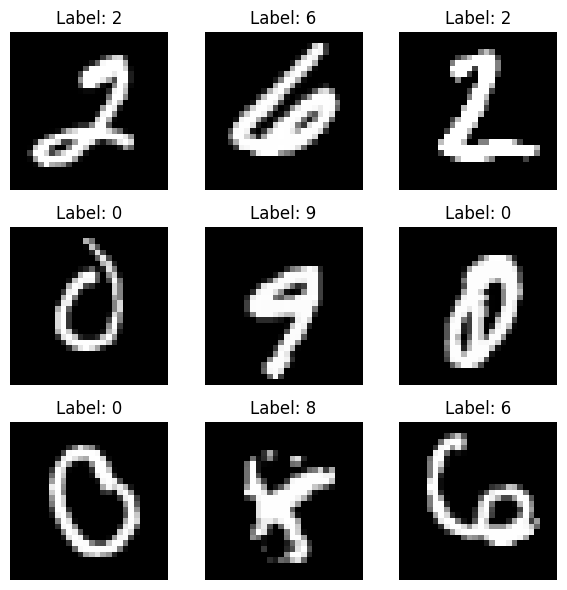

In [3]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

plt.figure(figsize=(6, 6))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i][0], cmap="gray")
    plt.title(f"Label: {labels[i].item()}")
    plt.axis("off")
plt.tight_layout()
plt.savefig("mnist_digits.svg")
plt.show()

## Đào tạo và đánh giá🔗
Giờ dữ liệu đã sẵn sàng, đã đến lúc dạy các mô hình cách đọc chữ số viết tay. Để làm điều này, chúng ta sẽ định nghĩa một vòng lặp huấn luyện và đánh giá tiêu chuẩn bằng cách sử dụng cấu trúc đặc trưng của PyTorch. Chúng ta cũng sẽ theo dõi độ phức tạp của mô hình bằng một bộ đếm tham số đơn giản — hữu ích khi so sánh các kiến ​​trúc khác nhau.

## Thiết lập thiết bị và các kỷ nguyên🔗
Đầu tiên, chúng ta kiểm tra xem GPU có sẵn hay không. Nếu có, quá trình huấn luyện sẽ diễn ra trên CUDA; nếu không, chúng ta sẽ chuyển sang sử dụng CPU. Chúng ta cũng thiết lập một khoảng thời gian huấn luyện hợp lý:

In [4]:
import torch

EPOCHS = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Năm chu kỳ huấn luyện có vẻ không nhiều, nhưng trên tập dữ liệu MNIST, chừng đó thường đủ để đạt được kết quả tốt đáng ngạc nhiên—ngay cả với các mô hình cơ bản.

## Vòng lặp huấn luyện🔗
Đây là train()hàm của chúng ta. Nó đơn giản hết mức có thể: thiết lập mô hình ở chế độ huấn luyện, lặp qua các batch, tính toán tổn thất và cập nhật trọng số.

In [5]:
def train(model, loader, optimizer, criterion):
    model.train()
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        output = model(x)
        loss = criterion(output, y)
        loss.backward()
        optimizer.step()

## Vòng lặp đánh giá🔗
Sau khi huấn luyện, chúng tôi đánh giá trên tập dữ liệu kiểm thử. Mô hình được thiết lập ở eval()chế độ cơ bản, đạo hàm riêng bị vô hiệu hóa, và chúng tôi thu thập hai chỉ số: độ chính xác và tổn thất entropy chéo trung bình.

In [6]:
import torch.nn.functional as F

def test(model, loader):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            output = model(x)
            loss = F.cross_entropy(output, y)
            total_loss += loss.item()
            preds = output.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    avg_loss = total_loss / len(loader)  # average over batches
    return correct / total, avg_loss

## Số lượng tham số🔗
Trước khi so sánh các kiến ​​trúc, điều hữu ích là biết mỗi kiến ​​trúc có bao nhiêu tham số có thể huấn luyện được. Tiện ích nhỏ này sẽ cung cấp cho chúng ta số lượng đó:

In [7]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Người chạy thử nghiệm🔗
Cuối cùng, chúng tôi kết hợp mọi thứ vào một hàm duy nhất để huấn luyện mô hình, tính thời gian xử lý, đánh giá trên tập dữ liệu kiểm thử và in ra bản tóm tắt ngắn gọn:

In [8]:
import time
import torch.optim as optim
import torch.nn as nn

def run_experiment(model_class, name):
    model = model_class().to(DEVICE)
    optimizer = optim.Adam(model.parameters())
    criterion = nn.CrossEntropyLoss()

    print(f"\n{name} ({count_params(model)} parameters)")
    start = time.time()
    for epoch in range(EPOCHS):
        train(model, train_loader, optimizer, criterion)
    duration = time.time() - start

    acc, loss = test(model, test_loader)
    print(f"Test Accuracy: {acc * 100:.2f}% | Loss: {loss:.2f} | Learning time: {duration:.1f}s")

Cấu trúc này đủ linh hoạt để hoạt động với bất kỳ lớp mô hình nào bạn truyền vào — từ các mạng nơ-ron đa lớp đơn giản đến các mạng nơ-ron tích chập sâu phức tạp.

Trong phần tiếp theo, chúng ta sẽ định nghĩa và phân tích bốn kiến ​​trúc: MLP, TinyCNN, CNN, và StrongCNN.

## Mô hình 1: Mạng nơ-ron đa lớp (MLP)🔗
Kiến trúc đơn giản nhất mà chúng ta xem xét là Mạng nơ-ron đa lớp (MLP) cổ điển. Nó xử lý mỗi hình ảnh 28×28 như một vectơ phẳng gồm 784 pixel, bỏ qua cấu trúc không gian nhưng vẫn có thể học được các đặc điểm hữu ích thông qua các lớp kết nối đầy đủ.

In [9]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        h = 32  # number of hidden units
        self.model = nn.Sequential(
            nn.Flatten(),          # Flatten 28x28 image into a vector of length 784
            nn.Linear(28 * 28, h), # Fully connected layer: 784 → 32
            nn.ReLU(),             # Non-linear activation
            nn.Linear(h, 10)       # Output layer: 32 → 10 classes
        )

    def forward(self, x):
        return self.model(x)

## Giải thích🔗
* Hàm Flatten chuyển đổi ảnh đầu vào 2D thành vector 1D.
* Lớp tuyến tính đầu tiên chiếu vectơ đầu vào này vào không gian ẩn 32 chiều.
* Hàm kích hoạt ReLU đưa vào tính phi tuyến tính để học các mẫu phức tạp.
* Lớp Linear cuối cùng xuất ra các giá trị logit cho 10 lớp chữ số.
Mạng nơ-lan truyền đa lớp (MLP) nhỏ này có tương đối ít tham số và huấn luyện nhanh, nhưng nó không nắm bắt được mối quan hệ không gian giữa các pixel, hạn chế độ chính xác của nó trên dữ liệu hình ảnh.

In [10]:
run_experiment(MLP, "MLP")


MLP (25450 parameters)
Test Accuracy: 95.89% | Loss: 0.13 | Learning time: 45.2s


## Mô hình 2: TinyCNN — Một mạng nơ-ron tích chập tối giản🔗
Tiếp theo, chúng tôi giới thiệu một kiến ​​trúc TinyCNN đơn giản sử dụng các lớp tích chập để nắm bắt các mẫu không gian trong hình ảnh. Mô hình này nhẹ nhưng mạnh mẽ hơn nhiều so với MLP trong các tác vụ xử lý hình ảnh.

In [11]:
import torch.nn as nn

class TinyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 4, kernel_size=3, padding=1),   # 1x28x28 → 4x28x28
            nn.ReLU(),
            nn.MaxPool2d(2),                             # 4x14x14
            nn.Conv2d(4, 8, kernel_size=3, padding=1),   # 8x14x14
            nn.ReLU(),
            nn.MaxPool2d(2),                             # 8x7x7
            nn.Flatten(),
            nn.Linear(8 * 7 * 7, 10)                     # Direct to output layer
        )

    def forward(self, x):
        return self.net(x)

##Tổng quan về kiến ​​trúc🔗
* Mạng nơ-ron bắt đầu với một lớp tích chập chuyển đổi đầu vào từ 1 kênh thành 4 kênh, bảo toàn các chiều không gian bằng cách thêm phần đệm.
* Hàm kích hoạt ReLU bổ sung thêm tính phi tuyến tính.
* MaxPooling giảm một nửa kích thước không gian xuống còn 14×14, giúp giảm chi phí tính toán và đảm bảo tính bất biến về không gian.
* Phép tích chập thứ hai mở rộng bản đồ đặc trưng từ 4 lên 8 kênh.
Một hàm ReLU khác và phép gộp tối đa (max-pooling) giúp giảm kích thước bản đồ đặc trưng xuống còn 7×7.
* Cuối cùng, các đặc trưng được làm phẳng và truyền trực tiếp đến một lớp tuyến tính để xuất ra logit cho 10 lớp chữ số.

## Mô hình 3: CNN — Mạng nơ-ron tích chập cân bằng
Mô hình CNN dưới đây được thiết kế để duy trì sự cân bằng giữa số lượng tham số và hiệu năng. Nó mở rộng khả năng trích xuất đặc trưng TinyCNNbằng cách sử dụng nhiều bộ lọc hơn và một lớp tuyến tính ẩn trước khi đưa ra kết quả cuối cùng.

In [12]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),   # 1x28x28 → 8x28x28
            nn.ReLU(),
            nn.MaxPool2d(2),                             # 8x14x14
            nn.Conv2d(8, 16, kernel_size=3, padding=1),  # 16x14x14
            nn.ReLU(),
            nn.MaxPool2d(2),                             # 16x7x7
            nn.Flatten(),
            nn.Linear(16 * 7 * 7, 32),                   # Dense layer with 32 units
            nn.ReLU(),
            nn.Linear(32, 10)                            # Final output layer
        )

    def forward(self, x):
        return self.net(x)

## Phân tích kiến ​​trúc🔗
So với TinyCNN, mô hình này:

* Tăng gấp đôi số lượng bộ lọc tích chập (8 → 16), cho phép nó thu được các mẫu hình ảnh phong phú hơn.
* Thêm một lớp kết nối đầy đủ ẩn với 32 nơron trước lớp đầu ra. Lớp bổ sung này cải thiện khả năng kết hợp các đặc trưng đã trích xuất của mô hình trước khi đưa ra phân loại cuối cùng.
* Nó vẫn chỉ sử dụng hai lớp tích chập và hai lớp gộp – giúp nó có dung lượng và tốc độ tương đối nhẹ.

## Mô hình 4: StrongCNN — Một cỗ máy tích chập sâu mạnh mẽ
Đây StrongCNNlà một kiến ​​trúc sâu sắc và biểu cảm hơn, tích hợp nhiều lớp tích chập, số lượng kênh cao hơn và các kỹ thuật điều chỉnh như Dropoutđể ngăn ngừa hiện tượng quá khớp. Nó được lấy cảm hứng từ những thực tiễn tốt nhất của các mô hình thị giác lớn hơn nhưng vẫn đủ nhỏ gọn để huấn luyện nhanh chóng MNIST.

In [13]:
class StrongCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),   # 1x28x28 → 32x28x28
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),  # 32x28x28
            nn.ReLU(),
            nn.MaxPool2d(2),                  # 32x14x14
            nn.Dropout(0.25),

            nn.Conv2d(32, 64, 3, padding=1),  # 64x14x14
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),  # 64x14x14
            nn.ReLU(),
            nn.MaxPool2d(2),                  # 64x7x7
            nn.Dropout(0.25),

            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

## Phần kết luận🔗
Thí nghiệm này chứng minh cách các lựa chọn kiến ​​trúc ảnh hưởng đến hiệu suất trong mạng nơ-ron. Ngay cả với một tập dữ liệu đơn giản như MNIST:

* Mạng nơ-ron đa lớp (MLP) hoạt động được nhưng bỏ qua cấu trúc hình ảnh.
* Mạng nơ-ron tích chập (CNN) tận dụng các đặc điểm không gian để đạt được kết quả tốt hơn.
* Độ sâu và độ rộng giúp cải thiện độ chính xác nhưng làm tăng chi phí huấn luyện và nguy cơ quá khớp dữ liệu.
* Việc điều chỉnh tham số là rất cần thiết cho các mạng nơ-ron sâu hơn.
Các mô hình tích chập vượt trội hơn các mạng nơron đa lớp (MLP) không phải vì chúng "sâu hơn" hay "tinh vi hơn", mà vì chúng hiểu cách thức hoạt động của hình ảnh .

Những kết quả này phản ánh xu hướng rộng hơn được thấy trong các nghiên cứu tiên tiến nhất :

* Các mô hình tích chập vẫn là xương sống của việc phân loại MNIST, cung cấp các thiên kiến ​​quy nạp mạnh mẽ về cấu trúc hình ảnh.

* Các kỹ thuật như dropout, tăng cường dữ liệu và kiến ​​trúc mạng sâu là chìa khóa để cải thiện hiệu suất.

* Các mô hình tiên tiến hơn, chẳng hạn như mạng nơ-ron capsule, mô hình lai transformer và mô hình kết hợp , đã đẩy độ chính xác lên trên 99,85% , mặc dù các phương pháp này thường quá mức cần thiết đối với tập dữ liệu MNIST và đòi hỏi nhiều tài nguyên tính toán hơn.